# Taller 3 — Aprendizaje profundo: reconocimiento de caracteres manuscritos con otro conjunto de datos
**Inteligencia Computacional Aplicada · Maestría en Ciencias de la Información y las Comunicaciones · UDFJC**
**Estudiante:** Juan Felipe Rodríguez Galindo (20261595004) · **Docente:** Cesar Andrey Perdomo Charry

Este cuaderno repite el flujo del cuaderno resuelto por el docente (MNIST, MLP y CNN en PyTorch) sobre **KMNIST**
(caracteres *kuzushiji*: hiragana manuscrito japonés clásico, 10 clases, 28×28, 60 000 + 10 000 imágenes), completa los
cinco bloques `TODO` y añade una sección de **extras** que va más allá de lo pedido.

| | |
|---|---|
| **Dataset principal** | `KMNIST` (se puede cambiar en la celda de configuración; el código funciona igual con `FashionMNIST` y `MNIST`) |
| **Marco** | PyTorch + torchvision (CPU; sin GPU el taller completo tarda ~1 h por los extras, el núcleo ~3 min) |
| **TODO 1** | Conteo de imágenes por clase |
| **TODO 2** | `CNNPropia`: 2 bloques Conv + BatchNorm + ReLU + MaxPool, Dropout, < 200 000 parámetros |
| **TODO 3** | Bucle de entrenamiento (5 pasos) |
| **TODO 4** | Evaluación en prueba y par de clases más confundido |
| **TODO 5** | Aumento de datos por desplazamiento y comparación con/sin aumento |
| **Extras (Paso 7)** | 5 semillas + prueba pareada · ablación de componentes · profundidad · línea base MLP y CNN del docente · KMNIST vs FashionMNIST vs MNIST · tasa de aprendizaje · filtros y mapas de activación |

### Cómo leer este cuaderno
- Las celdas `verificar(...)` imprimen `[OK]` o `[REVISAR]`; todas deben salir en `[OK]`.
- Las **comparaciones** se hacen con varias semillas y con el *mismo* orden de lotes por semilla (ver Paso 5): con una sola
  semilla la diferencia entre dos configuraciones puede ser puro ruido.
- Las corridas costosas se guardan en `resultados/corridas.jsonl`; si el archivo existe, se reutilizan (`USAR_CACHE`).
  En Colab, sin ese archivo, todo se calcula desde cero.

## Paso 0. Entorno y configuración

In [1]:
# ---- Preparación del entorno (Colab ya trae PyTorch, torchvision y scikit-learn) ----
import random, time, hashlib, os, shutil, json
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import confusion_matrix

SEMILLA = 42                      # misma semilla = mismos resultados (reproducibilidad)
def fijar_semilla(s=SEMILLA):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
fijar_semilla()

dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", dispositivo)

def verificar(nombre, ok, pista=""):
    """Punto de control: imprime [OK] o [REVISAR] con una pista."""
    print(("[OK]      " if ok else "[REVISAR] ") + nombre + ("" if ok else "  ->  " + pista))
    return ok

# ---- Carpetas de salida (las figuras del informe salen de aquí) ----
CARPETA_RES, CARPETA_FIG = "resultados", "figuras"
for _c in (CARPETA_RES, CARPETA_FIG):
    os.makedirs(_c, exist_ok=True)

# ---- Paleta institucional UD (manual de marca) para todas las figuras ----
from cycler import cycler
UD = dict(azul="#1291C0", rojo="#ED3237", dorado="#B49739", verde="#00A859", plata="#98999A", sable="#373435")
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=[UD["azul"], UD["rojo"], UD["dorado"], UD["verde"], UD["plata"], UD["sable"]]),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
    "axes.edgecolor": UD["sable"], "axes.labelcolor": UD["sable"], "text.color": UD["sable"],
    "xtick.color": UD["sable"], "ytick.color": UD["sable"], "figure.dpi": 100, "savefig.dpi": 200,
    "savefig.bbox": "tight", "font.family": "serif",
})

PyTorch 2.14.1 | dispositivo: cpu


In [2]:
# ---- CONFIGURACIÓN: cambie solo estas líneas ----
DATASET = "KMNIST"      # "KMNIST" | "FashionMNIST" | "MNIST"
EPOCAS  = 5

# ---- Configuración de los extras (Paso 7) ----
EJECUTAR_EXTRAS = True              # False = solo el núcleo del taller (TODO 1 a 5)
USAR_CACHE      = True              # reutiliza resultados/corridas.jsonl si existe
SEMILLAS_PRINCIPALES = [0, 1, 2, 3, 4]   # comparación con/sin aumento
SEMILLAS_SECUNDARIAS = [0, 1, 2]         # ablación, líneas base y otros datasets

## Paso 1 — Los datos
Funciones auxiliares **del cuaderno del docente** (sin modificar su lógica). Se cargan las imágenes como tensores
**N × 1 × 28 × 28** en [0, 1], se separan 5 000 imágenes de validación y se normaliza con la media y la desviación
estándar **solo del entrenamiento** (para no filtrar información del futuro).

| `torchvision` | `o` | `ki` | `su` | `tsu` | `na` | `ha` | `ma` | `ya` | `re` | `wo` |
|---|---|---|---|---|---|---|---|---|---|---|
| hiragana | お | き | す | つ | な | は | ま | や | れ | を |

In [3]:
# ---- Funciones de datos (no necesita modificarlas) ----
def cargar_dataset(nombre="MNIST", raiz="datos"):
    """Descarga el conjunto con torchvision y devuelve tensores en [0,1] con forma N x 1 x 28 x 28.
    Si no hay internet, usa un conjunto de RESPALDO (digits de scikit-learn) y avisa."""
    from torchvision import datasets
    try:
        clase = getattr(datasets, nombre)
        tr = clase(raiz, train=True, download=True)
        te = clase(raiz, train=False, download=True)
        Xtr = tr.data.float().div(255).unsqueeze(1)
        Xte = te.data.float().div(255).unsqueeze(1)
        return Xtr, tr.targets.clone(), Xte, te.targets.clone(), list(tr.classes), False
    except Exception as e:
        print("AVISO: no se pudo descargar", nombre, "->", type(e).__name__)
        print("Se usa un conjunto de RESPALDO (sklearn digits: 1797 imágenes 8x8 escaladas a 28x28).")
        print("Sirve para probar el código, pero NO es", nombre, "y las exactitudes serán distintas.")
        from sklearn.datasets import load_digits
        d = load_digits()
        X = torch.tensor(d.images, dtype=torch.float32).div(16).unsqueeze(1)
        X = F.interpolate(X, size=28, mode="bilinear", align_corners=False)
        y = torch.tensor(d.target, dtype=torch.long)
        g = torch.Generator().manual_seed(SEMILLA)
        p = torch.randperm(len(y), generator=g)
        n_te = len(y) // 5
        return X[p[n_te:]], y[p[n_te:]], X[p[:n_te]], y[p[:n_te]], [str(i) for i in range(10)], True


def preparar_datos(nombre="MNIST", n_val=5000, batch=64):
    """Carga, separa entrenamiento/validación/prueba y normaliza SOLO con estadísticos de entrenamiento."""
    Xtr, ytr, Xte, yte, clases, respaldo = cargar_dataset(nombre)
    n_val = min(n_val, len(ytr) // 10)
    g = torch.Generator().manual_seed(SEMILLA)
    p = torch.randperm(len(ytr), generator=g)
    iv, it = p[:n_val], p[n_val:]
    Xt, yt, Xv, yv = Xtr[it], ytr[it], Xtr[iv], ytr[iv]
    media, desv = Xt.mean().item(), Xt.std().item()
    norm = lambda X: (X - media) / desv
    d = dict(nombre=nombre, clases=clases, respaldo=respaldo, media=media, desv=desv,
             Xraw_tr=Xt, Xraw_te=Xte,
             X_tr=norm(Xt), y_tr=yt, X_val=norm(Xv), y_val=yv, X_te=norm(Xte), y_te=yte)
    d["dl_tr"] = DataLoader(TensorDataset(d["X_tr"], yt), batch_size=batch, shuffle=True, generator=g)
    d["dl_val"] = DataLoader(TensorDataset(d["X_val"], yv), batch_size=512)
    d["dl_te"] = DataLoader(TensorDataset(d["X_te"], d["y_te"]), batch_size=512)
    return d


def mostrar_muestras(X, y, clases, n=16, titulo="", guardar=None):
    fig, ejes = plt.subplots(2, n // 2, figsize=(1.4 * n // 2, 3.2))
    for ax, i in zip(ejes.ravel(), range(n)):
        ax.imshow(X[i, 0], cmap="gray"); ax.set_title(clases[int(y[i])], fontsize=9); ax.axis("off")
    fig.suptitle(titulo); plt.tight_layout()
    if guardar: fig.savefig(f"{CARPETA_FIG}/{guardar}.png")      # (añadido) guarda la figura para el informe
    plt.show()

Dataset: KMNIST | clases: ['o', 'ki', 'su', 'tsu', 'na', 'ha', 'ma', 'ya', 're', 'wo']
Entrenamiento: (55000, 1, 28, 28) | Validación: (5000, 1, 28, 28) | Prueba: (10000, 1, 28, 28)
Media y desviación usadas (solo entrenamiento): 0.1918  0.3484


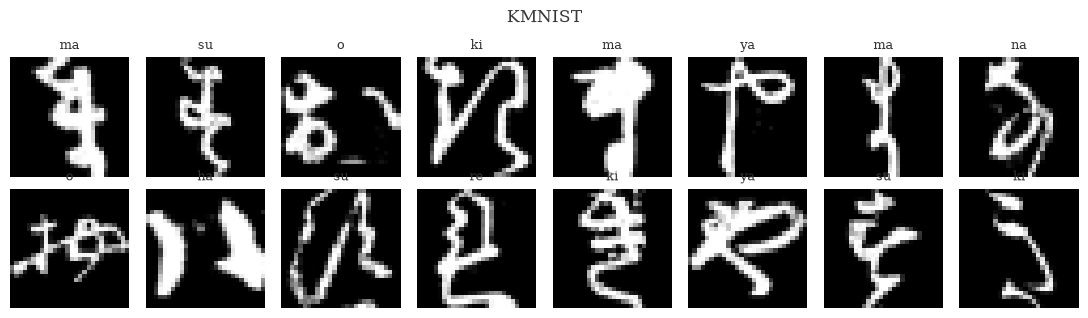

In [4]:
datos = preparar_datos(DATASET)
clases = datos["clases"]
print("Dataset:", DATASET, "| clases:", clases)
print("Entrenamiento:", tuple(datos["X_tr"].shape), "| Validación:", tuple(datos["X_val"].shape), "| Prueba:", tuple(datos["X_te"].shape))
print("Media y desviación usadas (solo entrenamiento): %.4f  %.4f" % (datos["media"], datos["desv"]))
mostrar_muestras(datos["Xraw_tr"], datos["y_tr"], clases, 16, DATASET, guardar="f01_muestras")

In [5]:
# ---- Funciones de evaluación y gráficas (las del docente; solo se añadió el parámetro opcional `guardar`) ----
@torch.no_grad()
def evaluar(modelo, dl):
    """Devuelve pérdida media, exactitud, etiquetas reales y predichas."""
    modelo.eval(); ls, ok, n = 0.0, 0, 0
    reales, preds = [], []
    for xb, yb in dl:
        xb, yb = xb.to(dispositivo), yb.to(dispositivo)
        salida = modelo(xb)
        ls += F.cross_entropy(salida, yb, reduction="sum").item()
        pred = salida.argmax(1)
        ok += (pred == yb).sum().item(); n += len(yb)
        reales.append(yb.cpu()); preds.append(pred.cpu())
    return ls / n, ok / n, torch.cat(reales).numpy(), torch.cat(preds).numpy()


def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)


def graficar_curvas(hist, titulo="", guardar=None):
    ep = range(1, len(hist["loss"]) + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
    a1.plot(ep, hist["loss"], "o-", label="entrenamiento"); a1.plot(ep, hist["val_loss"], "s-", label="validación")
    a1.set_xlabel("época"); a1.set_ylabel("pérdida (entropía cruzada)"); a1.legend(); a1.grid(alpha=.3)
    a2.plot(ep, hist["acc"], "o-", label="entrenamiento"); a2.plot(ep, hist["val_acc"], "s-", label="validación")
    a2.set_xlabel("época"); a2.set_ylabel("exactitud"); a2.legend(); a2.grid(alpha=.3)
    fig.suptitle(titulo); plt.tight_layout()
    if guardar: fig.savefig(f"{CARPETA_FIG}/{guardar}.png")
    plt.show()


def graficar_confusion(cm, clases, titulo="Matriz de confusión", guardar=None):
    fig, ax = plt.subplots(figsize=(5.5, 5))
    im = ax.imshow(cm, cmap="Blues"); fig.colorbar(im, fraction=0.046)
    ax.grid(False)
    ax.set_xticks(range(len(clases))); ax.set_yticks(range(len(clases)))
    ax.set_xticklabels(clases, rotation=60, ha="right", fontsize=8); ax.set_yticklabels(clases, fontsize=8)
    ax.set_xlabel("predicha"); ax.set_ylabel("real"); ax.set_title(titulo)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if cm[i, j] > 0:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6,
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout()
    if guardar: fig.savefig(f"{CARPETA_FIG}/{guardar}.png")
    plt.show()

## Paso 1 — TODO 1: explorar el conjunto
Cuente cuántas imágenes hay de cada clase en entrenamiento. Comente en una línea si el conjunto está balanceado.

{'o': 5492, 'ki': 5493, 'su': 5450, 'tsu': 5531, 'na': 5512, 'ha': 5516, 'ma': 5479, 'ya': 5480, 're': 5533, 'wo': 5514}
[OK]      TODO 1
Clase más frecuente: re (5533) | menos frecuente: su (5450) | razón máx/mín = 1.015


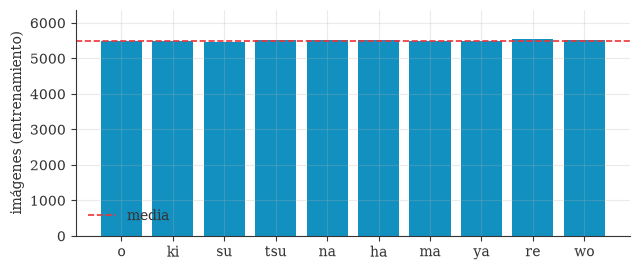

In [6]:
# TODO 1: cuente las imágenes por clase en datos["y_tr"]
conteo = torch.bincount(datos["y_tr"], minlength=len(clases))

if conteo is not None:
    print(dict(zip(clases, conteo.tolist())))
verificar("TODO 1", conteo is not None and int(conteo.sum()) == len(datos["y_tr"]), "debe sumar el número de imágenes de entrenamiento")

# Comentario cuantitativo: razón entre la clase más y la menos frecuente
razon = conteo.max().item() / conteo.min().item()
print(f"Clase más frecuente: {clases[int(conteo.argmax())]} ({conteo.max().item()}) | menos frecuente: "
      f"{clases[int(conteo.argmin())]} ({conteo.min().item()}) | razón máx/mín = {razon:.3f}")

fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.bar(clases, conteo.numpy(), color=UD["azul"]); ax.axhline(conteo.float().mean(), color=UD["rojo"], ls="--", lw=1.2, label="media")
ax.set_ylabel("imágenes (entrenamiento)"); ax.set_ylim(0, conteo.max().item() * 1.15); ax.legend(frameon=False)
plt.tight_layout(); fig.savefig(f"{CARPETA_FIG}/f02_conteo_clases.png"); plt.show()

**TODO 1 — ¿Balanceado?** Sí. Entre 5 450 (*su*) y 5 533 (*re*) imágenes por clase, una razón máx/mín de **1,015**: ninguna clase domina. Por eso la exactitud global es una medida razonable aquí; aun así se revisa la matriz de confusión porque un promedio puede esconder una clase mala (y lo hace: ver Paso 4).

## Paso 2 — TODO 2: diseñar su arquitectura
Se define `CNNPropia` con **dos bloques** `Conv2d(3×3, relleno 1) → BatchNorm2d → ReLU → MaxPool2d(2)` y un `Dropout` antes de la capa lineal final.

| Capa | Salida | Parámetros |
|---|---|---|
| Entrada | 1×28×28 | 0 |
| Conv 3×3, 16 filtros (relleno 1) | 16×28×28 | 16·(1·9+1) = 160 |
| BatchNorm2d(16) | 16×28×28 | 2·16 = 32 |
| ReLU + MaxPool 2×2 | 16×14×14 | 0 |
| Conv 3×3, 32 filtros (relleno 1) | 32×14×14 | 32·(16·9+1) = 4 640 |
| BatchNorm2d(32) | 32×14×14 | 2·32 = 64 |
| ReLU + MaxPool 2×2 | 32×7×7 | 0 |
| Aplanar + Dropout(0,3) | 1 568 | 0 |
| Lineal 1568→10 | 10 | 1568·10+10 = 15 690 |

**Total: 20 586 parámetros** (< 200 000). El relleno 1 conserva el tamaño espacial antes de cada *pooling*, de modo
que los trazos cercanos al borde de la imagen no pierdan información. La clase acepta `canales`, `usar_bn` y `p_drop`
para poder hacer la **ablación** del Paso 7 con la misma definición.

*Pregunta para el informe — ¿por qué incluyó cada componente y qué esperaba de él?*
- **Convolución 3×3:** rasgos locales (bordes, curvas, cruces de trazos) con pesos compartidos → pocos parámetros e invarianza parcial a traslaciones.
- **BatchNorm2d:** normaliza cada canal por lote; estabiliza y acelera el entrenamiento y tolera tasas de aprendizaje mayores.
- **ReLU:** no linealidad barata que no satura para valores positivos.
- **MaxPool 2×2:** reduce a la mitad el tamaño y da tolerancia a pequeños desplazamientos del trazo.
- **Dropout (0,3):** regulariza la capa lineal final (donde están el 76 % de los parámetros).

In [7]:
# TODO 2: complete __init__ y forward
class CNNPropia(nn.Module):
    def __init__(self, canales=(16, 32), usar_bn=True, p_drop=0.3, n_clases=10):
        super().__init__()
        # TODO 2a: defina sus capas (mín. 2 bloques Conv2d + BatchNorm2d + ReLU + MaxPool2d, y un Dropout)
        bloques, c_in = [], 1
        for c_out in canales:
            bloques.append(nn.Sequential(
                nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),        # conserva el tamaño espacial
                nn.BatchNorm2d(c_out) if usar_bn else nn.Identity(),
                nn.ReLU(),
                nn.MaxPool2d(2)))                                        # divide el tamaño entre 2
            c_in = c_out
        self.bloques = nn.ModuleList(bloques)
        lado = 28 // (2 ** len(canales))                                 # 28 -> 14 -> 7 (-> 3 con 3 bloques)
        self.drop = nn.Dropout(p_drop)                                   # apaga neuronas al azar SOLO en entrenamiento
        self.fc = nn.Linear(c_in * lado * lado, n_clases)                # 32*7*7 = 1568 características de entrada
    def forward(self, x):
        # TODO 2b: aplique sus capas y devuelva los logits (lote x 10)
        for b in self.bloques:
            x = b(x)
        return self.fc(self.drop(x.flatten(1)))                          # logits (la softmax va dentro de la pérdida)

In [8]:
# Verificación automática TODO 2
try:
    modelo = CNNPropia().to(dispositivo).eval()
    salida = modelo(datos["X_tr"][:4].to(dispositivo))
    n_par = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    print("Parámetros:", n_par)
    verificar("TODO 2: salida de forma (4, 10)", tuple(salida.shape) == (4, 10), "la última capa debe dar 10 logits")
    verificar("TODO 2: menos de 200 000 parámetros", n_par < 200_000, "reduzca filtros o neuronas")
    verificar("TODO 2: usa BatchNorm2d", any(isinstance(m, nn.BatchNorm2d) for m in modelo.modules()), "agregue nn.BatchNorm2d")
    verificar("TODO 2: usa Dropout", any(isinstance(m, nn.Dropout) for m in modelo.modules()), "agregue nn.Dropout")
    verificar("TODO 2: al menos 2 capas convolucionales", sum(isinstance(m, nn.Conv2d) for m in modelo.modules()) >= 2, "agregue otro bloque")
    verificar("Extra: coincide con la tabla (160 + 32 + 4 640 + 64 + 15 690 = 20 586)", n_par == 20586, "recalcule la tabla")
except Exception as e:
    print("[REVISAR] TODO 2 ->", type(e).__name__, e)

Parámetros: 20586
[OK]      TODO 2: salida de forma (4, 10)
[OK]      TODO 2: menos de 200 000 parámetros
[OK]      TODO 2: usa BatchNorm2d
[OK]      TODO 2: usa Dropout
[OK]      TODO 2: al menos 2 capas convolucionales
[OK]      Extra: coincide con la tabla (160 + 32 + 4 640 + 64 + 15 690 = 20 586)


## Paso 3 — TODO 3: el bucle de entrenamiento
Los cinco pasos de una iteración, **en este orden**: borrar gradientes → propagar → pérdida → retropropagar → actualizar.
Si no se borran los gradientes, PyTorch **acumula** `dL/dW` de lotes anteriores y la actualización mezcla direcciones
que ya no corresponden al lote actual. Es lo mismo que el Taller 2, pero con `autograd` calculando $\delta$ por nosotros.

*(Se añadieron dos parámetros opcionales — `verbose` y `registro` — para guardar la pérdida por iteración y los filtros
de la primera capa; el cuerpo del bucle, con los 5 pasos, es el que pide el taller.)*

In [9]:
def _filtros_conv1(modelo):
    """Copia de los pesos de la primera convolución (C_out x 1 x 3 x 3), para ver cómo 'aprenden' los filtros."""
    conv = next(m for m in modelo.modules() if isinstance(m, nn.Conv2d))
    return conv.weight.detach().cpu().clone()


def entrenar(modelo, dl_tr, dl_val, epocas=3, lr=1e-3, aumentar=None, verbose=True, registro=None):
    """Bucle de entrenamiento con Adam y entropía cruzada. Devuelve el historial por época."""
    modelo.to(dispositivo)
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    hist = {"loss": [], "acc": [], "val_loss": [], "val_acc": [], "t": []}
    if registro is not None:
        registro["perdida_paso"] = []
        registro["filtros_conv1"] = [_filtros_conv1(modelo)]          # época 0 = inicialización
    for ep in range(epocas):
        modelo.train(); ls, ok, n = 0.0, 0, 0
        t0 = time.time()
        for xb, yb in dl_tr:
            xb, yb = xb.to(dispositivo), yb.to(dispositivo)
            if aumentar is not None:
                xb = aumentar(xb)
            # ===== TODO 3: los 5 pasos de una iteración de entrenamiento =====
            opt.zero_grad()                              # 1) borrar gradientes de la iteración anterior
            salida = modelo(xb)                          # 2) propagación hacia adelante (logits)
            perdida = F.cross_entropy(salida, yb)        # 3) pérdida: softmax + entropía cruzada
            perdida.backward()                           # 4) retropropagación: calcula dL/dW
            opt.step()                                   # 5) Adam actualiza los pesos
            # ===== fin TODO 3 =====
            l = perdida.item()
            ls += l * len(yb); ok += (salida.argmax(1) == yb).sum().item(); n += len(yb)
            if registro is not None:
                registro["perdida_paso"].append(l)
        vl, va, _, _ = evaluar(modelo, dl_val)
        hist["loss"].append(ls / n); hist["acc"].append(ok / n)
        hist["val_loss"].append(vl); hist["val_acc"].append(va); hist["t"].append(time.time() - t0)
        if registro is not None:
            registro["filtros_conv1"].append(_filtros_conv1(modelo))
        if verbose:
            print(f"época {ep+1}/{epocas}  pérdida {ls/n:.4f}  exact {ok/n:.4f}  |  val_pérdida {vl:.4f}  val_exact {va:.4f}  ({time.time()-t0:.0f}s)")
    return hist

época 1/5  pérdida 0.3744  exact 0.8856  |  val_pérdida 0.1732  val_exact 0.9496  (10s)


época 2/5  pérdida 0.1955  exact 0.9399  |  val_pérdida 0.1391  val_exact 0.9566  (10s)


época 3/5  pérdida 0.1574  exact 0.9511  |  val_pérdida 0.1069  val_exact 0.9686  (10s)


época 4/5  pérdida 0.1316  exact 0.9600  |  val_pérdida 0.0890  val_exact 0.9734  (10s)


época 5/5  pérdida 0.1175  exact 0.9631  |  val_pérdida 0.0889  val_exact 0.9740  (10s)


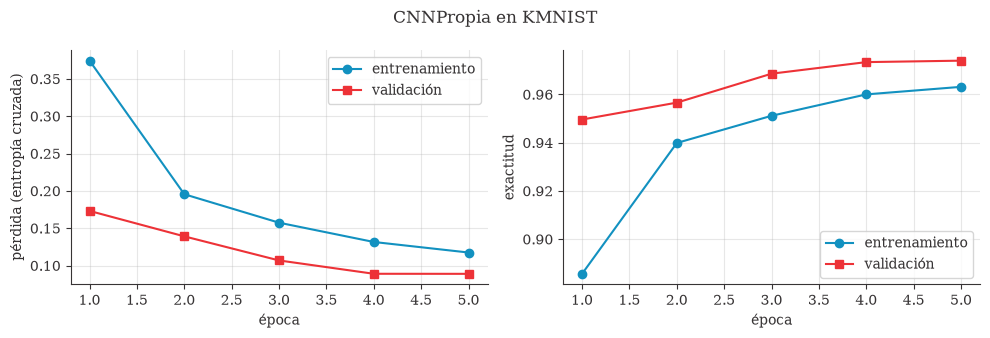

[OK]      TODO 3: la pérdida de entrenamiento baja entre la primera y la última época
[OK]      TODO 3: exactitud de validación > 80 %
[OK]      Extra: exactitud de validación > 90 % (valor esperado con datos reales)


True

In [10]:
# Entrenamiento y verificación TODO 3
fijar_semilla()
modelo = CNNPropia()
registro_main = {}
hist = entrenar(modelo, datos["dl_tr"], datos["dl_val"], epocas=EPOCAS, lr=1e-3, registro=registro_main)
graficar_curvas(hist, f"CNNPropia en {DATASET}", guardar="f03_curvas_cnnpropia")
verificar("TODO 3: la pérdida de entrenamiento baja entre la primera y la última época", hist["loss"][-1] < hist["loss"][0], "revise los 5 pasos y su orden")
verificar("TODO 3: exactitud de validación > 80 %", hist["val_acc"][-1] > 0.80, "con KMNIST o FashionMNIST reales debería superar 90 %; revise el entrenamiento")
verificar("Extra: exactitud de validación > 90 % (valor esperado con datos reales)", hist["val_acc"][-1] > 0.90, "revise el entrenamiento")

**TODO 3 — Lectura de las curvas.** La pérdida de entrenamiento baja de 0,374 a 0,118 y la exactitud de validación sube de 94,96 % a **97,40 %** en 5 épocas; sigue mejorando, pero la pérdida de validación ya casi se aplana (0,0890 → 0,0889 entre las épocas 4 y 5).
Dos detalles que conviene no malinterpretar: (1) la curva de *entrenamiento* se promedia **durante** la época y con *dropout* activo, por eso queda por encima de la de validación (que se mide al final y en modo evaluación); no es una señal de "validación mejor que entrenamiento" en sentido real. (2) No hay sobreajuste visible todavía: la brecha entre exactitud de entrenamiento (en modo evaluación) y validación es de solo ≈ 0,9 puntos.

## Paso 4 — TODO 4: evaluación en prueba y errores más frecuentes
El conjunto de prueba se usa **una sola vez** para estimar el desempeño de este modelo (`modelo`); ninguna decisión de
diseño (arquitectura, épocas, tasa de aprendizaje) se tomó mirándolo, solo con validación. Se busca el par
(clase real, clase predicha) con más errores y se **inspeccionan imágenes concretas** para explicarlo.

Exactitud en prueba: 0.9185   pérdida: 0.2821   (815 errores de 10000)


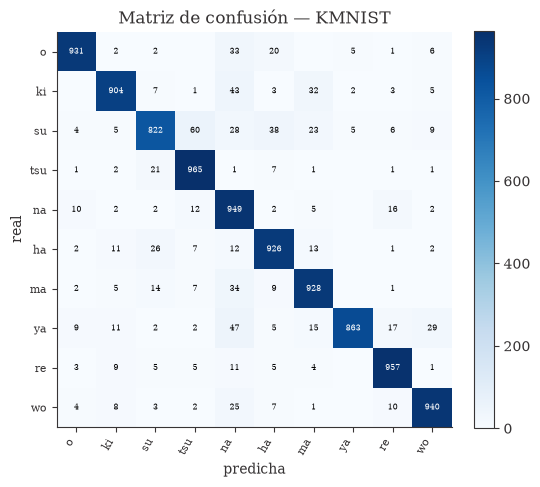

Par más confundido (real, predicha): ('su', 'tsu') -> 60 veces
[OK]      TODO 4

Top-5 pares (real -> predicha):
    su -> tsu   60 veces   (sentido contrario: 21)
    ya -> na    47 veces   (sentido contrario: 0)
    ki -> na    43 veces   (sentido contrario: 2)
    su -> ha    38 veces   (sentido contrario: 26)
    ma -> na    34 veces   (sentido contrario: 5)
[OK]      La suma de la matriz de confusión = tamaño del conjunto de prueba


np.True_

In [11]:
perd_te, acc_te, y_real, y_pred = evaluar(modelo, datos["dl_te"])
print(f"Exactitud en prueba: {acc_te:.4f}   pérdida: {perd_te:.4f}   ({int(round((1-acc_te)*len(y_real)))} errores de {len(y_real)})")
cm = confusion_matrix(y_real, y_pred)
graficar_confusion(cm, clases, f"Matriz de confusión — {DATASET}", guardar="f04_matriz_confusion")

# TODO 4: encuentre el par (real, predicha) con más errores, como tupla de dos enteros
_f = cm.copy(); np.fill_diagonal(_f, 0)
par = tuple(int(v) for v in np.unravel_index(np.argmax(_f), _f.shape))

if par is not None:
    print("Par más confundido (real, predicha):", (clases[par[0]], clases[par[1]]), "->", int(_f[par]), "veces")
verificar("TODO 4", par is not None and _f[tuple(par)] == _f.max(), "busque el máximo fuera de la diagonal")

# Extra: los 5 pares más confundidos y la confusión en ambos sentidos
_g = _f.copy()
print("\nTop-5 pares (real -> predicha):")
for _ in range(5):
    i, j = np.unravel_index(np.argmax(_g), _g.shape)
    print(f"  {clases[i]:>4} -> {clases[j]:<4} {_g[i, j]:>3} veces   (sentido contrario: {_f[j, i]})")
    _g[i, j] = 0
verificar("La suma de la matriz de confusión = tamaño del conjunto de prueba", cm.sum() == len(y_real), "")

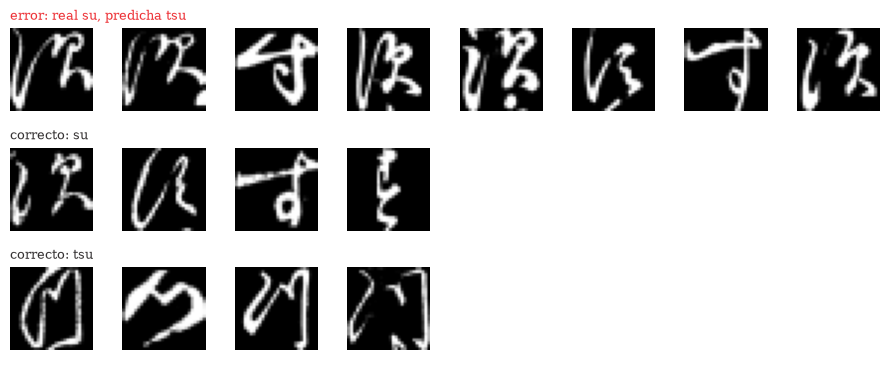

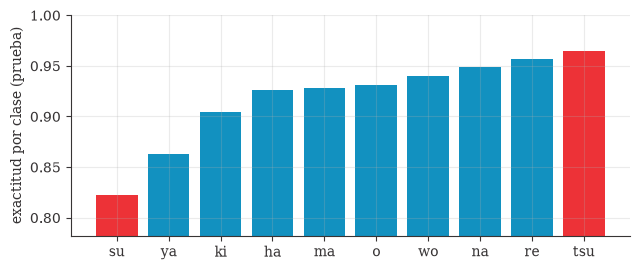

{'su': 0.822, 'ya': 0.863, 'ki': 0.904, 'ha': 0.926, 'ma': 0.928, 'o': 0.931, 'wo': 0.94, 'na': 0.949, 're': 0.957, 'tsu': 0.965}


In [12]:
# Imágenes concretas del par más confundido: errores (real -> predicha) y, a modo de contraste, ejemplos correctos de ambas clases
r, p_ = par
idx_err = np.where((y_real == r) & (y_pred == p_))[0][:8]
idx_r = np.where((y_real == r) & (y_pred == r))[0][:4]
idx_p = np.where((y_real == p_) & (y_pred == p_))[0][:4]
filas = [("error: real %s, predicha %s" % (clases[r], clases[p_]), idx_err),
         ("correcto: %s" % clases[r], idx_r), ("correcto: %s" % clases[p_], idx_p)]
fig, ejes = plt.subplots(3, 8, figsize=(9, 3.8))
for fila, (titulo, idx) in zip(ejes, filas):
    for k, ax in enumerate(fila):
        ax.axis("off"); ax.grid(False)
        if k < len(idx):
            ax.imshow(datos["Xraw_te"][idx[k], 0], cmap="gray")
    fila[0].set_title(titulo, loc="left", fontsize=9, color=UD["rojo"] if "error" in titulo else UD["sable"])
plt.tight_layout(); fig.savefig(f"{CARPETA_FIG}/f05_par_confundido.png"); plt.show()

# Exactitud por clase (qué clases son más difíciles en general)
acc_clase = cm.diagonal() / cm.sum(1)
fig, ax = plt.subplots(figsize=(6.5, 2.8))
orden = np.argsort(acc_clase)
ax.bar([clases[i] for i in orden], acc_clase[orden], color=[UD["rojo"] if i in par else UD["azul"] for i in orden])
ax.set_ylim(acc_clase.min() - 0.04, 1.0); ax.set_ylabel("exactitud por clase (prueba)")
plt.tight_layout(); fig.savefig(f"{CARPETA_FIG}/f06_acc_por_clase.png"); plt.show()
print({clases[i]: round(float(acc_clase[i]), 3) for i in orden})

**TODO 4 — Resultado y por qué se confunden.**

*Exactitud en prueba: **91,85 %** (815 errores de 10 000), frente a 97,40 % en validación.* Esa brecha de 5,5 puntos **no es un error del código**: se repite con las 5 semillas (validación ≈ 97,1 %, prueba ≈ 92,1 %) y **no aparece** con MNIST ni FashionMNIST (Paso 7.4, donde ambas coinciden dentro de ±0,1 puntos). La validación sale de una partición aleatoria del conjunto de entrenamiento, así que comparte su distribución; la prueba oficial de KMNIST evidentemente no la comparte del todo (es más difícil). La causa exacta no la medimos; es una hipótesis razonable que haya variantes de escritura o escritores que solo aparecen en prueba. Consecuencia práctica: **para reportar rendimiento hay que mirar la prueba, no la validación**, y la validación es útil para *comparar* configuraciones, no para predecir el número final.

*Par más confundido: real **su** → predicha **tsu** (60 veces; en sentido contrario solo 21).* La clase *su* es además la peor (82,2 % de exactitud). Mirando las imágenes de la figura: los *su* mal clasificados son casi todos una **variante cursiva** distinta de la que domina en la clase (un trazo vertical largo con ganchos a la derecha, sin el bucle característico de す), y esa forma se parece a varias grafías de *tsu* correctamente clasificadas (trazos verticales con un cierre lateral). Es decir, hay **variación dentro de la clase** (el kuzushiji conserva formas alternativas de un mismo carácter) y poca variación entre las dos clases para esas variantes. Que la confusión sea asimétrica (60 vs 21) sugiere que *tsu* actúa como "atractor" de esas variantes raras de *su*. Algo similar ocurre con *na*: es la clase predicha en tres de los cinco pares más frecuentes (*ya*→*na* 47, *ki*→*na* 43, *ma*→*na* 34) y, en cambio, casi nunca se confunde en sentido inverso.

## Paso 5 — TODO 5: aumento de datos (experimento)
El **aumento de datos** crea variaciones de las imágenes de entrenamiento para que la red generalice mejor. Se implementa
un desplazamiento aleatorio de hasta ±2 píxeles y se compara el modelo **con y sin** aumento.

**Un detalle de rigor.** En `preparar_datos` el `DataLoader` de entrenamiento comparte un único generador `g`, cuyo estado
avanza en cada corrida: dos entrenamientos con "la misma semilla" ven los lotes en **órdenes distintos** y la comparación no
es realmente pareada. Aquí se crea un cargador **nuevo por corrida** (`nuevo_loader`) para que, dada una semilla, la
inicialización, el orden de los lotes y el *dropout* sean idénticos con y sin aumento. Y, como el propio taller advierte,
se repite con **5 semillas** antes de afirmar algo.

In [13]:
# TODO 5: devuelva xb desplazado al azar hasta +-max_px píxeles (un desplazamiento por lote es suficiente)
def aumentar_desplazamiento(xb, max_px=2):
    dy, dx = (int(v) for v in torch.randint(-max_px, max_px + 1, (2,)))      # un desplazamiento por lote
    return torch.roll(xb, shifts=(dy, dx), dims=(2, 3))

[OK]      TODO 5: conserva la forma del lote
[OK]      TODO 5: modifica el lote en algunas llamadas


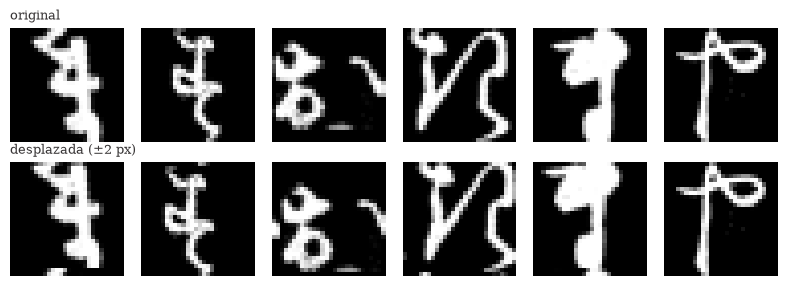

In [14]:
# Verificación automática TODO 5
_x = datos["X_tr"][:8].to(dispositivo)
_cambios = [not torch.equal(aumentar_desplazamiento(_x), _x) for _ in range(30)]
verificar("TODO 5: conserva la forma del lote", aumentar_desplazamiento(_x).shape == _x.shape, "no cambie el tamaño")
verificar("TODO 5: modifica el lote en algunas llamadas", any(_cambios), "ahora devuelve xb sin cambios")

fig, ejes = plt.subplots(2, 6, figsize=(8, 2.9))
for k in range(6):
    ejes[0, k].imshow(datos["Xraw_tr"][k, 0], cmap="gray"); ejes[0, k].axis("off"); ejes[0, k].grid(False)
    ejes[1, k].imshow(aumentar_desplazamiento(datos["X_tr"][k:k+1])[0, 0], cmap="gray"); ejes[1, k].axis("off"); ejes[1, k].grid(False)
ejes[0, 0].set_title("original", loc="left", fontsize=9); ejes[1, 0].set_title("desplazada (±2 px)", loc="left", fontsize=9)
plt.tight_layout(); fig.savefig(f"{CARPETA_FIG}/f07_ejemplo_aumento.png"); plt.show()

In [15]:
# ---- Infraestructura de corridas: cargador pareado por semilla + caché de resultados ----
def nuevo_loader(d, semilla, batch=64):
    """Cargador de entrenamiento con generador propio: misma semilla => mismo orden de lotes."""
    g = torch.Generator().manual_seed(semilla)
    return DataLoader(TensorDataset(d["X_tr"], d["y_tr"]), batch_size=batch, shuffle=True, generator=g)

CACHE = f"{CARPETA_RES}/corridas.jsonl"
def _leer_cache():
    if not (USAR_CACHE and os.path.exists(CACHE)):
        return {}
    filas = [json.loads(l) for l in open(CACHE, encoding="utf-8") if l.strip()]
    return {(r["exp"], r["etiqueta"], r["dataset"], r["semilla"], r["epocas"], r["lr"]): r for r in filas}
CORRIDAS = _leer_cache()
print(f"Corridas en caché: {len(CORRIDAS)}")

def correr(exp, etiqueta, fabrica, d, semilla, epocas=None, lr=1e-3, aumentar=None):
    """Entrena `fabrica()` con una semilla y devuelve un dict con las métricas finales (usa/guarda caché)."""
    epocas = epocas or EPOCAS
    clave = (exp, etiqueta, d["nombre"], semilla, epocas, lr)
    if clave in CORRIDAS:
        return CORRIDAS[clave]
    fijar_semilla(semilla)
    m = fabrica()
    t0 = time.time()
    h = entrenar(m, nuevo_loader(d, semilla), d["dl_val"], epocas, lr, aumentar, verbose=False)
    dur = time.time() - t0
    _, acc_tr_eval, _, _ = evaluar(m, DataLoader(TensorDataset(d["X_tr"], d["y_tr"]), batch_size=512))
    lt, at, yr, yp = evaluar(m, d["dl_te"])
    r = dict(exp=exp, etiqueta=etiqueta, dataset=d["nombre"], semilla=semilla, epocas=epocas, lr=lr,
             params=contar_parametros(m), hist=h, acc_tr_eval=acc_tr_eval, val_acc=h["val_acc"][-1],
             val_loss=h["val_loss"][-1], test_acc=at, test_loss=lt, tiempo=dur,
             acc_clase=(confusion_matrix(yr, yp).diagonal() / np.bincount(yr, minlength=10)).tolist())
    CORRIDAS[clave] = r
    with open(CACHE, "a", encoding="utf-8") as f:
        f.write(json.dumps(r) + "\n")
    print(f"  {exp}/{etiqueta} {d['nombre']} semilla {semilla}: val {r['val_acc']:.4f} prueba {at:.4f} ({dur:.0f}s)")
    return r

def tabla(exp, etiquetas, dataset=None):
    """Media ± desviación (ddof=1) por etiqueta para un experimento."""
    dataset = dataset or DATASET
    filas = []
    for et in etiquetas:
        rs = [r for r in CORRIDAS.values() if r["exp"] == exp and r["etiqueta"] == et and r["dataset"] == dataset]
        f = lambda k: np.array([r[k] for r in rs], dtype=float)
        sd = lambda a: a.std(ddof=1) if len(a) > 1 else 0.0
        filas.append(dict(etiqueta=et, n=len(rs), params=rs[0]["params"],
                          tr_eval=f("acc_tr_eval").mean(), val=f("val_acc").mean(), val_sd=sd(f("val_acc")),
                          te=f("test_acc").mean(), te_sd=sd(f("test_acc")), brecha=(f("acc_tr_eval") - f("val_acc")).mean(),
                          t=f("tiempo").mean()))
    return filas

def imprimir_tabla(filas):
    print(f"{'configuración':<28}{'n':>2} {'params':>8} {'train(eval)':>12} {'valid':>16} {'prueba':>16} {'brecha':>8} {'t(s)':>6}")
    for f in filas:
        print(f"{f['etiqueta']:<28}{f['n']:>2} {f['params']:>8} {f['tr_eval']:>12.4f} "
              f"{f['val']:.4f} ± {f['val_sd']:.4f}  {f['te']:.4f} ± {f['te_sd']:.4f} {f['brecha']:>+8.4f} {f['t']:>6.0f}")

Corridas en caché: 53


In [16]:
# Comparación con y sin aumento: 5 semillas, mismo orden de lotes e inicialización por semilla
from scipy import stats

fab = lambda: CNNPropia()
print("Entrenando (las corridas ya en caché se saltan)...")
for s in SEMILLAS_PRINCIPALES:
    correr("aumento", "sin aumento", fab, datos, s)
    correr("aumento", "con aumento (lote)", fab, datos, s, aumentar=aumentar_desplazamiento)

filas_aug = tabla("aumento", ["sin aumento", "con aumento (lote)"])
print(); imprimir_tabla(filas_aug)

def pareada(exp, a, b, campo="test_acc", dataset=None):
    dataset = dataset or DATASET
    get = lambda et: np.array([CORRIDAS[(exp, et, dataset, s, EPOCAS, 1e-3)][campo] for s in SEMILLAS_PRINCIPALES])
    A, B = get(a), get(b); dif = B - A
    t, p = stats.ttest_rel(B, A)
    return dif, p

for campo in ("val_acc", "test_acc"):
    dif, p = pareada("aumento", "sin aumento", "con aumento (lote)", campo)
    print(f"\n{campo}: con - sin = {dif.mean():+.4f} ± {dif.std(ddof=1):.4f}   (mejor en {int((dif>0).sum())}/{len(dif)} semillas, t pareada p = {p:.3f})")
print("\nAviso: con n = 5 la prueba t tiene poca potencia; úsela como orientación, no como veredicto.")

Entrenando (las corridas ya en caché se saltan)...

configuración                n   params  train(eval)            valid           prueba   brecha   t(s)
sin aumento                  5    20586       0.9800 0.9710 ± 0.0027  0.9213 ± 0.0028  +0.0090     49
con aumento (lote)           5    20586       0.9730 0.9709 ± 0.0013  0.9181 ± 0.0015  +0.0021     50

val_acc: con - sin = -0.0000 ± 0.0027   (mejor en 1/5 semillas, t pareada p = 0.976)

test_acc: con - sin = -0.0033 ± 0.0029   (mejor en 1/5 semillas, t pareada p = 0.067)

Aviso: con n = 5 la prueba t tiene poca potencia; úsela como orientación, no como veredicto.


**TODO 5 — ¿Mejoró el aumento?** **No de forma apreciable.** Con 5 semillas y el mismo orden de lotes por semilla:

| comparado con "sin aumento" | validación | prueba |
|---|---|---|
| desplazamiento por lote (el del taller) | −0,00 ± 0,27 pts (mejor en 1/5 semillas) | **−0,33 ± 0,29 pts** (1/5; *t* pareada *p* = 0,067) |
| desplazamiento por muestra (extra) | +0,12 ± 0,31 pts (3/5; *p* = 0,43) | −0,25 ± 0,43 pts (1/5; *p* = 0,27) |

Lo que **sí** cambia es la brecha entre exactitud de entrenamiento (en modo evaluación) y validación: baja de **0,90** puntos sin aumento a **0,21** (lote) y **0,22** (por muestra). Es decir, el aumento *regulariza* (la red memoriza menos), pero esa menor memorización **no se tradujo en mejor generalización**. Posibles razones, que son hipótesis y no se probaron por separado: (a) con 5 épocas casi no hay sobreajuste que corregir; (b) la convolución con *max-pooling* ya da tolerancia a desplazamientos pequeños, así que ±2 px aporta poca información nueva; (c) `torch.roll` es circular y reinserta por el borde opuesto lo que sale, lo que a veces crea artefactos; (d) lo que falla en prueba no parece ser una traslación sino variantes de escritura (Paso 4), que este aumento no cubre. Con una semilla se habría podido "ver" una mejora o un empeoramiento según cuál se eligiera: ese es el motivo de repetir.

## Paso 6 — (Opcional, para quienes trabajan en MATLAB) exportar las imágenes
MATLAB y su app **Deep Network Designer** leen las imágenes desde carpetas con un subdirectorio por clase. Esta celda guarda
las imágenes en esa estructura y genera un `.zip`. Luego, en MATLAB:

```matlab
imds = imageDatastore("dataset_imagenes", IncludeSubfolders=true, LabelSource="foldernames");
```

In [17]:
def exportar_a_carpetas(X_raw, y, clases, carpeta="dataset_imagenes", max_por_clase=1000, comprimir=True):
    """Guarda imágenes PNG en carpeta/<clase>/NNNN.png: la estructura que MATLAB lee con
    imageDatastore(carpeta, IncludeSubfolders=true, LabelSource="foldernames") y con Deep Network Designer."""
    from PIL import Image
    if os.path.isdir(carpeta):
        shutil.rmtree(carpeta)
    cont = {}
    for i in range(len(y)):
        c = int(y[i]); nombre = str(clases[c]).replace("/", "_").replace(" ", "_")
        if cont.get(c, 0) >= max_por_clase:
            continue
        cont[c] = cont.get(c, 0) + 1
        os.makedirs(os.path.join(carpeta, nombre), exist_ok=True)
        arr = (X_raw[i, 0].numpy() * 255).round().astype("uint8")
        Image.fromarray(arr, mode="L").save(os.path.join(carpeta, nombre, f"{cont[c]:04d}.png"))
    total = sum(cont.values())
    print(f"Se guardaron {total} imágenes en {len(cont)} carpetas dentro de '{carpeta}'.")
    if comprimir:
        ruta = shutil.make_archive(carpeta, "zip", carpeta)
        print("Archivo comprimido:", ruta)
        return ruta
    return carpeta

In [18]:
ruta_zip = exportar_a_carpetas(datos["Xraw_tr"], datos["y_tr"], clases, carpeta="datos/dataset_imagenes", max_por_clase=1000)
try:
    from google.colab import files      # solo existe en Colab
    files.download(ruta_zip)
except ImportError:
    print("No está en Colab: el archivo quedó en", ruta_zip)

Se guardaron 10000 imágenes en 10 carpetas dentro de 'datos/dataset_imagenes'.


Archivo comprimido: /Users/juferoga/repos/ud/maestria/mcic/semestre-2/mcic-computational-intelligence/2.Talleres/3.Taller/desarrollo/datos/dataset_imagenes.zip
No está en Colab: el archivo quedó en /Users/juferoga/repos/ud/maestria/mcic/semestre-2/mcic-computational-intelligence/2.Talleres/3.Taller/desarrollo/datos/dataset_imagenes.zip


# Paso 7 — Extras: más allá del taller
Las preguntas que el taller deja abiertas, contestadas con evidencia. Todas las comparaciones usan los mismos datos, las
mismas épocas y semillas pareadas; las cifras son **media ± desviación** (ddof = 1) sobre las semillas indicadas.

| Extra | Pregunta |
|---|---|
| 7.1 | ¿El aumento *por muestra* (cada imagen su propio desplazamiento) mejora lo que el desplazamiento *por lote* no logra? |
| 7.2 | ¿Qué aporta cada componente de `CNNPropia` (BatchNorm, Dropout) y qué pasa con un tercer bloque? |
| 7.3 | ¿Cuánto gana la CNN respecto al MLP y a la CNN del docente en KMNIST? |
| 7.4 | ¿Es KMNIST más difícil que MNIST? ¿y que FashionMNIST? |
| 7.5 | ¿Se confirma, en KMNIST, el resultado del docente sobre la tasa de aprendizaje? |
| 7.6 | ¿Qué "ven" los filtros y cómo cambian durante el entrenamiento? |

## 7.1 Aumento por muestra
`torch.roll` con un único desplazamiento por lote mueve las 64 imágenes **igual**; con aumento *por muestra* cada imagen
recibe su propio $(\Delta y, \Delta x) \in [-2, 2]^2$, lo que da 25 variantes por imagen en lugar de 25 variantes por lote.

[OK]      7.1: conserva la forma
[OK]      7.1: imágenes idénticas reciben desplazamientos distintos
[OK]      7.1: el aumento por lote desplaza todas igual
Entrenando aumento por muestra...

configuración                n   params  train(eval)            valid           prueba   brecha   t(s)
sin aumento                  5    20586       0.9800 0.9710 ± 0.0027  0.9213 ± 0.0028  +0.0090     49
con aumento (lote)           5    20586       0.9730 0.9709 ± 0.0013  0.9181 ± 0.0015  +0.0021     50
con aumento (por muestra)    5    20586       0.9743 0.9722 ± 0.0013  0.9189 ± 0.0024  +0.0022     56
val_acc   con aumento (lote)         - sin aumento = -0.0000 ± 0.0027  (1/5 semillas, p = 0.976)
val_acc   con aumento (por muestra)  - sin aumento = +0.0012 ± 0.0031  (3/5 semillas, p = 0.430)
test_acc  con aumento (lote)         - sin aumento = -0.0033 ± 0.0029  (1/5 semillas, p = 0.067)
test_acc  con aumento (por muestra)  - sin aumento = -0.0025 ± 0.0043  (1/5 semillas, p = 0.269)


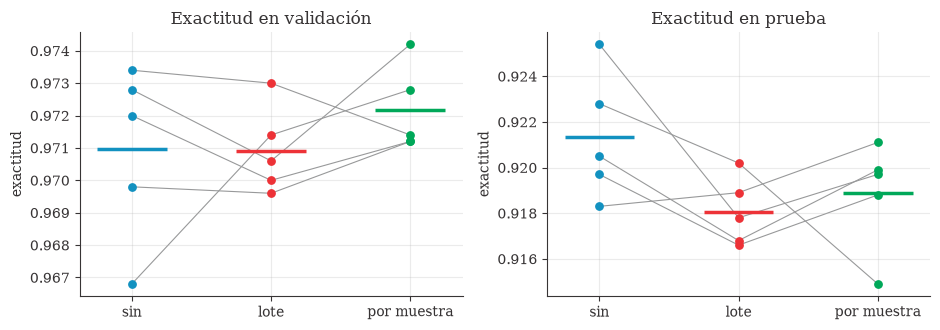

In [19]:
def aumentar_por_muestra(xb, max_px=2):
    """Un desplazamiento aleatorio distinto para CADA imagen del lote (25 grupos de torch.roll)."""
    n = len(xb)
    dy = torch.randint(-max_px, max_px + 1, (n,), device=xb.device)
    dx = torch.randint(-max_px, max_px + 1, (n,), device=xb.device)
    out = xb.clone()
    for a in range(-max_px, max_px + 1):
        for b in range(-max_px, max_px + 1):
            m = (dy == a) & (dx == b)
            if m.any():
                out[m] = torch.roll(xb[m], shifts=(a, b), dims=(2, 3))
    return out

_x = datos["X_tr"][:64].to(dispositivo); _y = aumentar_por_muestra(_x)
verificar("7.1: conserva la forma", _y.shape == _x.shape, "")
_rep = datos["X_tr"][:1].repeat(64, 1, 1, 1).to(dispositivo)     # 64 copias de la MISMA imagen
verificar("7.1: imágenes idénticas reciben desplazamientos distintos", torch.unique(aumentar_por_muestra(_rep).flatten(1), dim=0).shape[0] > 3, "")
verificar("7.1: el aumento por lote desplaza todas igual", torch.unique(aumentar_desplazamiento(_rep).flatten(1), dim=0).shape[0] == 1, "")

if EJECUTAR_EXTRAS:
    print("Entrenando aumento por muestra...")
    for s in SEMILLAS_PRINCIPALES:
        correr("aumento", "con aumento (por muestra)", fab, datos, s, aumentar=aumentar_por_muestra)
    filas_aug3 = tabla("aumento", ["sin aumento", "con aumento (lote)", "con aumento (por muestra)"])
    print(); imprimir_tabla(filas_aug3)
    for campo in ("val_acc", "test_acc"):
        for et in ("con aumento (lote)", "con aumento (por muestra)"):
            dif, p = pareada("aumento", "sin aumento", et, campo)
            print(f"{campo:<9} {et:<26} - sin aumento = {dif.mean():+.4f} ± {dif.std(ddof=1):.4f}  ({int((dif>0).sum())}/{len(dif)} semillas, p = {p:.3f})")

    # Figura: puntos por semilla (cada punto = una semilla; la línea gris une la misma semilla)
    et3 = ["sin aumento", "con aumento (lote)", "con aumento (por muestra)"]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 3.4))
    for ax, campo, tit in ((a1, "val_acc", "validación"), (a2, "test_acc", "prueba")):
        M = np.array([[CORRIDAS[("aumento", et, DATASET, s, EPOCAS, 1e-3)][campo] for et in et3] for s in SEMILLAS_PRINCIPALES])
        for fila in M: ax.plot(range(3), fila, color=UD["plata"], lw=.8, zorder=1)
        for k, col in enumerate((UD["azul"], UD["rojo"], UD["verde"])):
            ax.scatter(np.full(len(M), k), M[:, k], color=col, s=28, zorder=2)
            ax.hlines(M[:, k].mean(), k - .25, k + .25, color=col, lw=2.5, zorder=3)
        ax.set_xticks(range(3)); ax.set_xticklabels(["sin", "lote", "por muestra"]); ax.set_title(f"Exactitud en {tit}"); ax.set_ylabel("exactitud")
    plt.tight_layout(); fig.savefig(f"{CARPETA_FIG}/f08_aumento_semillas.png"); plt.show()

**7.1 — Lectura.** El aumento *por muestra* da 25 variantes por imagen en lugar de 25 por lote, pero el resultado es el mismo en esencia: validación +0,12 pts y prueba −0,25 pts frente a "sin aumento", ambos dentro del ruido entre semillas (σ ≈ 0,3 a 0,4 pts). Lo único consistente es la reducción de la brecha de memorización. En el gráfico, las líneas grises unen la misma semilla: se ve que no hay un orden estable entre las tres configuraciones.

### 7.1b ¿Y con más épocas?
Con 5 épocas la red todavía **no** sobreajusta, así que un regularizador tiene poco que corregir. El aumento suele rendir
cuando el modelo tiene tiempo de memorizar. Se repite la comparación con **15 épocas** (3 semillas): sin aumento vs. aumento
por muestra.

Entrenando 15 épocas...

configuración                n   params  train(eval)            valid           prueba   brecha   t(s)
sin aumento                  3    20586       0.9932 0.9823 ± 0.0018  0.9415 ± 0.0018  +0.0109    149
con aumento (por muestra)    3    20586       0.9848 0.9808 ± 0.0018  0.9396 ± 0.0014  +0.0040    162
val_acc   por muestra - sin = -0.0015 ± 0.0034  (1/3 semillas)
test_acc  por muestra - sin = -0.0019 ± 0.0006  (0/3 semillas)


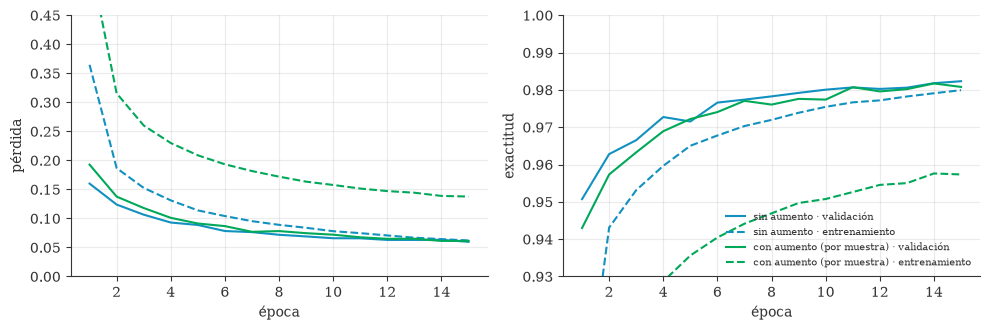

In [20]:
EPOCAS_LARGO = 15
if EJECUTAR_EXTRAS:
    print("Entrenando 15 épocas...")
    for s in SEMILLAS_SECUNDARIAS:
        correr("aumento_largo", "sin aumento", fab, datos, s, epocas=EPOCAS_LARGO)
        correr("aumento_largo", "con aumento (por muestra)", fab, datos, s, epocas=EPOCAS_LARGO, aumentar=aumentar_por_muestra)
    filas_largo = tabla("aumento_largo", ["sin aumento", "con aumento (por muestra)"])
    print(); imprimir_tabla(filas_largo)
    get = lambda et, k: np.array([CORRIDAS[("aumento_largo", et, DATASET, s, EPOCAS_LARGO, 1e-3)][k] for s in SEMILLAS_SECUNDARIAS])
    for campo in ("val_acc", "test_acc"):
        dif = get("con aumento (por muestra)", campo) - get("sin aumento", campo)
        print(f"{campo:<9} por muestra - sin = {dif.mean():+.4f} ± {dif.std(ddof=1):.4f}  ({int((dif>0).sum())}/{len(dif)} semillas)")

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4)); ep = np.arange(1, EPOCAS_LARGO + 1)
    for et, col in (("sin aumento", UD["azul"]), ("con aumento (por muestra)", UD["verde"])):
        H = [CORRIDAS[("aumento_largo", et, DATASET, s, EPOCAS_LARGO, 1e-3)]["hist"] for s in SEMILLAS_SECUNDARIAS]
        for ax, k, ls in ((a1, "val_loss", "-"), (a1, "loss", "--"), (a2, "val_acc", "-"), (a2, "acc", "--")):
            M = np.array([h[k] for h in H]); ax.plot(ep, M.mean(0), ls, color=col, label=f"{et} · {'validación' if k.startswith('val') else 'entrenamiento'}")
    a1.set_xlabel("época"); a1.set_ylabel("pérdida"); a2.set_xlabel("época"); a2.set_ylabel("exactitud"); a2.set_ylim(.93, 1.0); a1.set_ylim(0, .45)
    a2.legend(frameon=False, fontsize=7, loc="lower right")
    plt.tight_layout(); fig.savefig(f"{CARPETA_FIG}/f08b_aumento_15_epocas.png"); plt.show()

**7.1b — Lectura.** Con 15 épocas el modelo sin aumento sí empieza a memorizar (entrenamiento 99,32 % vs. validación 98,23 %: brecha 1,09 pts) y el aumento por muestra la recorta a **0,40 pts** (entrenamiento 98,48 %), pero otra vez sin mejorar lo que importa: validación −0,15 pts y prueba −0,19 pts (0 de 3 semillas mejor en prueba; 3 semillas solo permiten decir que *no hay evidencia de mejora*). Con ±2 px el aumento actúa como un regularizador que "cuesta" algo de ajuste y no compra generalización en este problema. Quedaría por probar un aumento distinto (rotaciones pequeñas, deformaciones elásticas) o más épocas.

## 7.2 Ablación de componentes y profundidad
Mismo diseño, una pieza menos cada vez (3 semillas). Las columnas `train(eval)` miden el entrenamiento **con el modelo en modo
evaluación** (sin *dropout*), para que la *brecha* `train(eval) − valid` sea comparable entre variantes.

Entrenando variantes...

configuración                n   params  train(eval)            valid           prueba   brecha   t(s)
completa (16-32, BN, Dropout) 3    20586       0.9806 0.9715 ± 0.0016  0.9210 ± 0.0016  +0.0090     48
sin BatchNorm                3    20490       0.9830 0.9747 ± 0.0025  0.9264 ± 0.0034  +0.0083     43
sin Dropout                  3    20586       0.9814 0.9669 ± 0.0020  0.9158 ± 0.0035  +0.0145     48
sin BatchNorm ni Dropout     3    20490       0.9872 0.9726 ± 0.0009  0.9256 ± 0.0051  +0.0146     42
3 bloques (16-32-64)         3    29290       0.9912 0.9823 ± 0.0016  0.9421 ± 0.0029  +0.0089     71


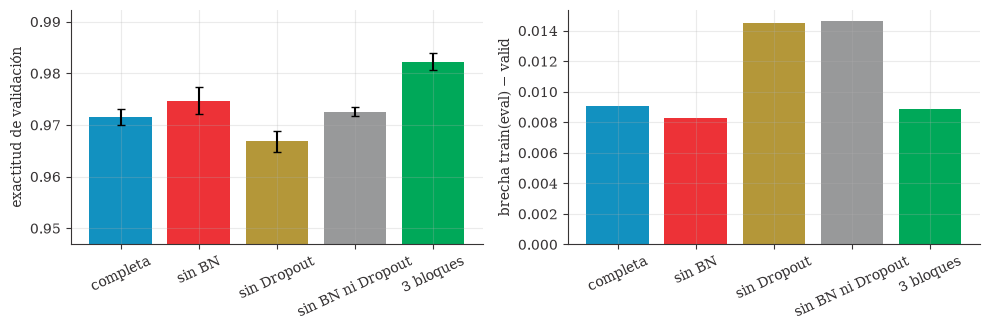

In [21]:
VARIANTES = {
    "completa (16-32, BN, Dropout)":  lambda: CNNPropia(),
    "sin BatchNorm":                  lambda: CNNPropia(usar_bn=False),
    "sin Dropout":                    lambda: CNNPropia(p_drop=0.0),
    "sin BatchNorm ni Dropout":       lambda: CNNPropia(usar_bn=False, p_drop=0.0),
    "3 bloques (16-32-64)":           lambda: CNNPropia(canales=(16, 32, 64)),
}
if EJECUTAR_EXTRAS:
    print("Entrenando variantes...")
    for s in SEMILLAS_SECUNDARIAS:
        for et, f in VARIANTES.items():
            # la 'completa' es la misma corrida de 'sin aumento': se reutiliza para no repetir
            if et.startswith("completa"):
                CORRIDAS[("ablacion", et, DATASET, s, EPOCAS, 1e-3)] = {**CORRIDAS[("aumento", "sin aumento", DATASET, s, EPOCAS, 1e-3)], "exp": "ablacion", "etiqueta": et}
            else:
                correr("ablacion", et, f, datos, s)
    filas_abl = tabla("ablacion", list(VARIANTES))
    print(); imprimir_tabla(filas_abl)

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
    et_cortas = ["completa", "sin BN", "sin Dropout", "sin BN ni Dropout", "3 bloques"]
    cols = [UD["azul"], UD["rojo"], UD["dorado"], UD["plata"], UD["verde"]]
    a1.bar(et_cortas, [f["val"] for f in filas_abl], yerr=[f["val_sd"] for f in filas_abl], color=cols, capsize=3)
    a1.set_ylim(min(f["val"] for f in filas_abl) - 0.02, max(f["val"] for f in filas_abl) + 0.01)
    a1.set_ylabel("exactitud de validación"); a1.tick_params(axis="x", rotation=25)
    a2.bar(et_cortas, [f["brecha"] for f in filas_abl], color=cols)
    a2.set_ylabel("brecha train(eval) − valid"); a2.tick_params(axis="x", rotation=25)
    plt.tight_layout(); fig.savefig(f"{CARPETA_FIG}/f09_ablacion.png"); plt.show()

**7.2 — Lectura** (3 semillas; σ de cada celda ≈ 0,1 a 0,5 pts).

| variante | Δ validación | Δ prueba | brecha |
|---|---|---|---|
| sin BatchNorm | +0,32 | +0,54 | 0,83 |
| sin Dropout | **−0,47** | **−0,52** | **1,45** |
| sin BatchNorm ni Dropout | +0,11 | +0,46 | 1,46 |
| **3 bloques (16-32-64)** | **+1,08** | **+2,11** | 0,89 |

- **Dropout sí aporta:** quitarlo sube la brecha de 0,90 a 1,45 pts y baja la exactitud en ≈ 0,5 pts (también con BN quitado: brecha 1,46).
- **BatchNorm no mejoró la exactitud final** a 5 épocas y η = 10⁻³ (la variante sin BN fue incluso 0,3 a 0,5 pts mejor, aunque con 3 semillas es indistinguible del ruido). Su beneficio esperado es otro, la estabilidad con tasas altas, y eso sí se ve en 7.5. Esto contradice la expectativa con la que se incluyó ("estabiliza y acelera") en cuanto a la *exactitud*, y se anota como tal.
- **El tercer bloque es la mejora clara:** +1,1 pts en validación y +2,1 en prueba con solo 8 704 parámetros más (+42 %), muy por encima del ruido. La brecha no cambia (0,89), o sea que la red base estaba **subajustada, no sobreajustada**: lo que faltaba era capacidad/campo receptivo, no más regularización.

## 7.3 Líneas base: MLP del docente y CNN del docente, sobre KMNIST
La misma comparación del Paso 2–3 del cuaderno resuelto, pero en el dataset del taller propuesto.

[OK]      7.3: la CNN del docente tiene 12 810 parámetros
[OK]      7.3: el MLP del docente tiene 101 770 parámetros
Entrenando líneas base...

configuración                n   params  train(eval)            valid           prueba   brecha   t(s)
MLP docente (784-128-10)     3   101770       0.9853 0.9545 ± 0.0018  0.8844 ± 0.0059  +0.0308      3
CNN docente (12 810 par.)    3    12810       0.9750 0.9687 ± 0.0004  0.9120 ± 0.0037  +0.0063     36
CNNPropia (20 586 par.)      3    20586       0.9806 0.9715 ± 0.0016  0.9210 ± 0.0016  +0.0090     48


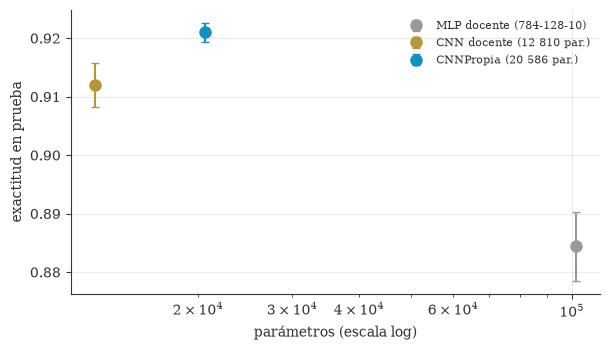

In [22]:
class CNNDocente(nn.Module):
    """La CNN del cuaderno resuelto del docente (12 810 parámetros en MNIST): sin BatchNorm, sin relleno, Dropout(0,25)."""
    def __init__(self, p_drop=0.25):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3); self.conv2 = nn.Conv2d(16, 32, kernel_size=3)
        self.drop = nn.Dropout(p_drop); self.fc = nn.Linear(32 * 5 * 5, 10)
    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        return self.fc(self.drop(x.flatten(1)))

BASES = {
    "MLP docente (784-128-10)": lambda: nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10)),
    "CNN docente (12 810 par.)": lambda: CNNDocente(),
}
verificar("7.3: la CNN del docente tiene 12 810 parámetros", contar_parametros(CNNDocente()) == 12810, "")
verificar("7.3: el MLP del docente tiene 101 770 parámetros", contar_parametros(BASES["MLP docente (784-128-10)"]()) == 101770, "")

if EJECUTAR_EXTRAS:
    print("Entrenando líneas base...")
    for s in SEMILLAS_SECUNDARIAS:
        for et, f in BASES.items():
            correr("bases", et, f, datos, s)
        CORRIDAS[("bases", "CNNPropia (20 586 par.)", DATASET, s, EPOCAS, 1e-3)] = {**CORRIDAS[("aumento", "sin aumento", DATASET, s, EPOCAS, 1e-3)], "exp": "bases", "etiqueta": "CNNPropia (20 586 par.)"}
    filas_bases = tabla("bases", ["MLP docente (784-128-10)", "CNN docente (12 810 par.)", "CNNPropia (20 586 par.)"])
    print(); imprimir_tabla(filas_bases)

    fig, ax = plt.subplots(figsize=(6.2, 3.6))
    for f, col in zip(filas_bases, (UD["plata"], UD["dorado"], UD["azul"])):
        ax.errorbar(f["params"], f["te"], yerr=f["te_sd"], fmt="o", color=col, capsize=3, ms=8, label=f["etiqueta"])
    ax.set_xscale("log"); ax.set_xlabel("parámetros (escala log)"); ax.set_ylabel("exactitud en prueba"); ax.legend(frameon=False, fontsize=8)
    plt.tight_layout(); fig.savefig(f"{CARPETA_FIG}/f10_bases_parametros.png"); plt.show()

**7.3 — Lectura** (3 semillas).

| modelo | parámetros | validación | prueba | brecha entren.−val. |
|---|---|---|---|---|
| MLP del docente | 101 770 | 95,45 % | 88,44 ± 0,59 % | 3,08 pts |
| CNN del docente | 12 810 | 96,87 % | 91,20 ± 0,37 % | 0,63 pts |
| **CNNPropia** | 20 586 | **97,15 %** | **92,10 ± 0,16 %** | 0,90 pts |

La convolución importa: la CNN más pequeña del docente (12 810 parámetros) supera en 2,8 pts al MLP, que tiene ocho veces más parámetros, y además generaliza mejor (brecha 0,6 vs 3,1 pts: el MLP memoriza). `CNNPropia` gana otros +0,9 pts sobre la CNN del docente gracias a la combinación de relleno, más ancho y *dropout*/BN, sin que este experimento permita atribuirlo a una sola pieza (ver 7.2). El precio está en tiempo (CPU): 3 s el MLP, 36 s la CNN del docente, 48 s la `CNNPropia`.

## 7.4 ¿Qué tan difícil es KMNIST? Mismo modelo, tres conjuntos
`CNNPropia` sin tocar nada en `MNIST` (el del docente), `FashionMNIST` y `KMNIST`. Se compara la exactitud y **cuántas
clases quedan por debajo del 90 %**, que es lo que la exactitud global esconde.

FashionMNIST listo: (55000, 1, 28, 28)


MNIST listo: (55000, 1, 28, 28)

MNIST         valid 0.9872 ± 0.0009 | prueba 0.9880 ± 0.0018 | peor clase 0.972 | clases < 90 %: 0.0
FashionMNIST  valid 0.9034 ± 0.0045 | prueba 0.9027 ± 0.0010 | peor clase 0.722 | clases < 90 %: 4.3
KMNIST        valid 0.9715 ± 0.0016 | prueba 0.9210 ± 0.0016 | peor clase 0.863 | clases < 90 %: 2.0


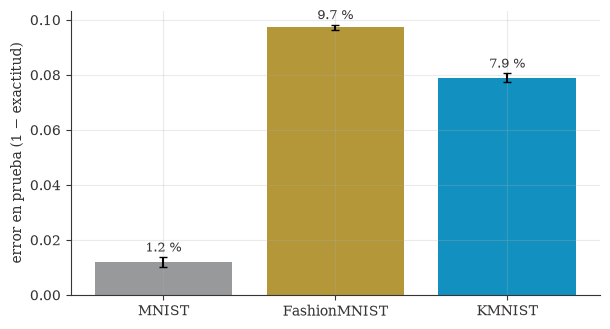

In [23]:
if EJECUTAR_EXTRAS:
    otros = {}
    for nombre in ("FashionMNIST", "MNIST"):
        otros[nombre] = preparar_datos(nombre)
        print(nombre, "listo:", tuple(otros[nombre]["X_tr"].shape))
        for s in SEMILLAS_SECUNDARIAS:
            correr("datasets", "CNNPropia", fab, otros[nombre], s)
    for s in SEMILLAS_SECUNDARIAS:
        CORRIDAS[("datasets", "CNNPropia", "KMNIST", s, EPOCAS, 1e-3)] = {**CORRIDAS[("aumento", "sin aumento", "KMNIST", s, EPOCAS, 1e-3)], "exp": "datasets", "etiqueta": "CNNPropia"}
    print()
    resumen_ds = {}
    for nombre in ("MNIST", "FashionMNIST", "KMNIST"):
        f = tabla("datasets", ["CNNPropia"], dataset=nombre)[0]
        rs = [r for r in CORRIDAS.values() if r["exp"] == "datasets" and r["dataset"] == nombre]
        peor = np.mean([min(r["acc_clase"]) for r in rs])
        bajo90 = np.mean([sum(a < 0.90 for a in r["acc_clase"]) for r in rs])
        resumen_ds[nombre] = dict(**f, peor_clase=peor, clases_bajo_90=bajo90)
        print(f"{nombre:<13} valid {f['val']:.4f} ± {f['val_sd']:.4f} | prueba {f['te']:.4f} ± {f['te_sd']:.4f} | "
              f"peor clase {peor:.3f} | clases < 90 %: {bajo90:.1f}")

    fig, ax = plt.subplots(figsize=(6.2, 3.4))
    nombres = ["MNIST", "FashionMNIST", "KMNIST"]
    ax.bar(nombres, [1 - resumen_ds[n]["te"] for n in nombres], yerr=[resumen_ds[n]["te_sd"] for n in nombres],
           color=[UD["plata"], UD["dorado"], UD["azul"]], capsize=3)
    ax.set_ylabel("error en prueba (1 − exactitud)")
    for k, n in enumerate(nombres):
        ax.text(k, 1 - resumen_ds[n]["te"] + resumen_ds[n]["te_sd"] + .002, f"{(1-resumen_ds[n]['te'])*100:.1f} %", ha="center", fontsize=9)
    plt.tight_layout(); fig.savefig(f"{CARPETA_FIG}/f11_datasets.png"); plt.show()

**7.4 — Lectura** (3 semillas).

| dataset | validación | prueba | val. − prueba | peor clase | clases < 90 % |
|---|---|---|---|---|---|
| MNIST | 98,72 % | 98,80 % | −0,1 pts | 97,2 % | 0 |
| FashionMNIST | 90,34 % | 90,27 % | +0,1 pts | 72,2 % | 4,3 |
| KMNIST | 97,15 % | 92,10 % | **≈ +5 pts** | 86,3 % | 2,0 |

La respuesta depende de la métrica. **Por exactitud en prueba**, KMNIST (92,1 %) es más difícil que MNIST (98,8 %) y algo más fácil que FashionMNIST (90,3 %); **por la peor clase**, KMNIST (86,3 %) está entre ambos y FashionMNIST es el peor (72,2 %, la clase *Shirt*). Lo que distingue a KMNIST es su **brecha entre validación y prueba** (≈ 5 pts frente a ≈ 0 en los otros dos): quien afine hiperparámetros con la validación de KMNIST obtendrá números optimistas.

## 7.5 Tasa de aprendizaje en KMNIST
El docente probó $10^{-1}, 10^{-3}, 10^{-5}$ con 2 épocas en MNIST. Aquí se repite en KMNIST con la `CNNPropia` y se
añaden $10^{-2}$ y $10^{-4}$ (1 semilla por valor; es un barrido exploratorio, no una comparación).

Entrenando tasas de aprendizaje (2 épocas)...

 lr        val_exact   val_pérdida
 0.1       0.8246      0.5836
 0.01      0.9670      0.1066
 0.001     0.9630      0.1281
 0.0001    0.9238      0.2653
 1e-05     0.7630      0.9683


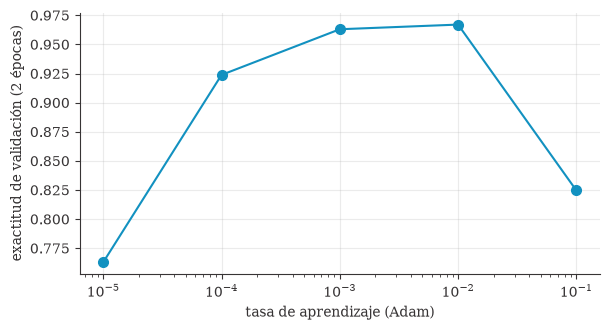

In [24]:
LRS = [1e-1, 1e-2, 1e-3, 1e-4, 1e-5]
if EJECUTAR_EXTRAS:
    print("Entrenando tasas de aprendizaje (2 épocas)...")
    res_lr = []
    for lr in LRS:
        r = correr("lr", f"lr={lr:g}", fab, datos, 0, epocas=2, lr=lr)
        res_lr.append((lr, r["val_acc"], r["val_loss"], r["hist"]["val_acc"]))
    print("\n lr        val_exact   val_pérdida")
    for lr, a, l, _ in res_lr:
        print(f" {lr:<9g} {a:.4f}      {l:.4f}")
    fig, ax = plt.subplots(figsize=(6.2, 3.4))
    ax.semilogx([x[0] for x in res_lr], [x[1] for x in res_lr], "o-", color=UD["azul"], ms=7)
    ax.set_xlabel("tasa de aprendizaje (Adam)"); ax.set_ylabel("exactitud de validación (2 épocas)")
    plt.tight_layout(); fig.savefig(f"{CARPETA_FIG}/f12_tasa_aprendizaje.png"); plt.show()

**7.5 — Lectura** (una sola semilla y 2 épocas: es exploratorio).

| η | 10⁻¹ | 10⁻² | 10⁻³ | 10⁻⁴ | 10⁻⁵ |
|---|---|---|---|---|---|
| exactitud de validación | 82,46 % | **96,70 %** | 96,30 % | 92,38 % | 76,30 % |

La forma es la esperada: demasiado grande o demasiado pequeña funcionan peor, con el óptimo entre 10⁻² y 10⁻³ (la diferencia entre ambos, 0,4 pts, no es concluyente con una semilla). **Una diferencia llamativa con el cuaderno del docente:** en MNIST su CNN con η = 10⁻¹ se quedó en ≈ 10 % (sin aprender); aquí, con η = 10⁻¹, la `CNNPropia` llega a 82,5 %. La comparación con el docente mezcla red y dataset, así que se hizo el control 7.5b: la misma `CNNPropia` sin BatchNorm. El resto del taller usó 10⁻³ por ser el valor del enunciado, aunque este barrido sugiere que 10⁻² habría sido igual o ligeramente mejor.

### 7.5b Control: ¿la tolerancia a η alto es de BatchNorm?
En el cuaderno del docente, η = 10⁻¹ deja la CNN en ≈ 10 %. Esa red no tiene BatchNorm, pero tampoco es la misma red ni el mismo dataset, así
que no se puede atribuir el fallo a la falta de BN. El control: `CNNPropia` **sin** BatchNorm con las mismas tasas, 2 épocas y la misma semilla.

In [25]:
if EJECUTAR_EXTRAS:
    print("Entrenando control sin BatchNorm (2 épocas)...")
    fab_sin_bn = lambda: CNNPropia(usar_bn=False)
    ctl = {}
    for lr in (1e-1, 1e-2, 1e-3):
        ctl[lr] = correr("lr_sin_bn", f"sin BN lr={lr:g}", fab_sin_bn, datos, 0, epocas=2, lr=lr)
    print("\n lr        con BN (val)   sin BN (val)")
    for lr in (1e-1, 1e-2, 1e-3):
        con = CORRIDAS[("lr", f"lr={lr:g}", DATASET, 0, 2, lr)]
        print(f" {lr:<9g} {con['val_acc']:.4f}         {ctl[lr]['val_acc']:.4f}")

Entrenando control sin BatchNorm (2 épocas)...

 lr        con BN (val)   sin BN (val)
 0.1       0.8246         0.0976
 0.01      0.9670         0.9262
 0.001     0.9630         0.9652


**7.5b — Lectura** (1 semilla, 2 épocas, misma red y mismo dataset).

| η | con BatchNorm | sin BatchNorm |
|---|---|---|
| 10⁻¹ | **82,46 %** | 9,76 % (no aprende: azar) |
| 10⁻² | 96,70 % | 92,62 % |
| 10⁻³ | 96,30 % | 96,52 % |

**El control confirma la hipótesis:** quitando solo BatchNorm, η = 10⁻¹ reproduce exactamente el fallo del cuaderno del docente (≈ 10 %), y con BatchNorm la misma red llega a 82,5 %. A η = 10⁻² también ayuda (+4,1 pts); a η = 10⁻³ no cambia nada (96,3 % vs 96,5 %), que es justo lo que mostró la ablación (7.2): **BatchNorm no mejora la exactitud con una η bien elegida, pero ensancha el rango de η que funciona.** Es una sola semilla, pero la diferencia a η = 10⁻¹ (73 puntos) está muy por encima de cualquier ruido plausible.

## 7.6 Mirar dentro de la red: filtros y mapas de activación
Los 16 filtros 3×3 de la primera capa, su **evolución** durante las 5 épocas del entrenamiento principal (`registro_main`) y
los mapas que producen sobre un carácter de prueba.

Cambio relativo medio de los filtros (||W_final - W_init|| / ||W_init||): 0.46
Similitud coseno inicio-final por filtro: [0.92, 0.82, 0.72, 0.92, 0.97, 0.94, 0.86, 0.93, 0.94, 0.96, 0.97, 0.63, 0.91, 0.87, 0.94, 0.89]


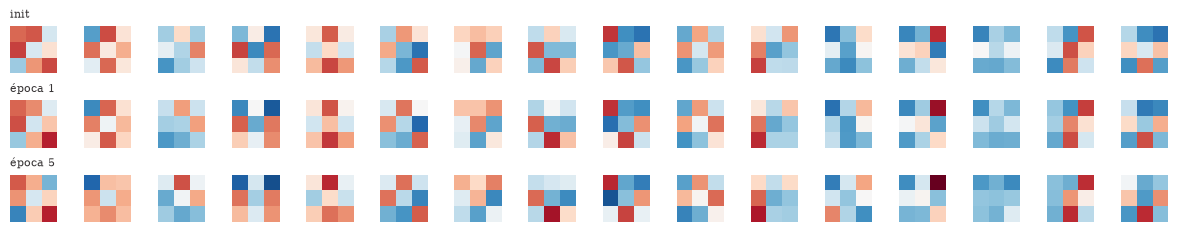

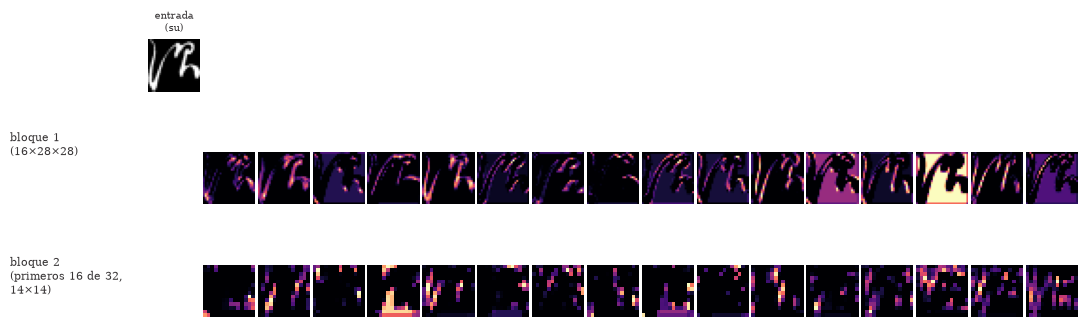

In [26]:
instantaneas = registro_main["filtros_conv1"]            # lista de (16,1,3,3): época 0 (init), 1, ..., EPOCAS
_w0, _wf = instantaneas[0].flatten(1), instantaneas[-1].flatten(1)
print(f"Cambio relativo medio de los filtros (||W_final - W_init|| / ||W_init||): {((_wf - _w0).norm(dim=1) / _w0.norm(dim=1)).mean():.2f}")
print("Similitud coseno inicio-final por filtro:", [round(v, 2) for v in torch.nn.functional.cosine_similarity(_w0, _wf, dim=1).tolist()])
etapas = [0, 1, EPOCAS]
fig, ejes = plt.subplots(len(etapas), 16, figsize=(12, 2.4))
for fila, e in zip(ejes, etapas):
    W = instantaneas[e][:, 0].numpy(); v = instantaneas[-1].abs().max().item()
    for k, ax in enumerate(fila):
        ax.imshow(W[k], cmap="RdBu_r", vmin=-v, vmax=v); ax.axis("off"); ax.grid(False)
    fila[0].set_title("init" if e == 0 else f"época {e}", loc="left", fontsize=8)
plt.tight_layout(); fig.savefig(f"{CARPETA_FIG}/f13_filtros_conv1.png"); plt.show()

# Mapas de activación del bloque 1 (tras Conv-BN-ReLU) y del bloque 2 para un carácter de prueba
@torch.no_grad()
def mapas(modelo, x):
    modelo.eval(); m1 = modelo.bloques[0][:3](x); m2 = modelo.bloques[1][:3](modelo.bloques[0](x))
    return m1[0].cpu(), m2[0].cpu()

k = int(np.where(y_real == par[0])[0][0])
m1, m2 = mapas(modelo.to(dispositivo), datos["X_te"][k:k+1].to(dispositivo))
fig = plt.figure(figsize=(12, 4.2)); gs = fig.add_gridspec(3, 17, wspace=.05, hspace=.15)
ax0 = fig.add_subplot(gs[0, 0]); ax0.imshow(datos["Xraw_te"][k, 0], cmap="gray"); ax0.axis("off"); ax0.grid(False); ax0.set_title(f"entrada\n({clases[y_real[k]]})", fontsize=7)
for c in range(16):
    ax = fig.add_subplot(gs[1, c + 1]); ax.imshow(m1[c], cmap="magma"); ax.axis("off"); ax.grid(False)
for c in range(16):
    ax = fig.add_subplot(gs[2, c + 1]); ax.imshow(m2[c], cmap="magma"); ax.axis("off"); ax.grid(False)
fig.text(.01, .55, "bloque 1\n(16×28×28)", fontsize=8); fig.text(.01, .22, "bloque 2\n(primeros 16 de 32,\n14×14)", fontsize=8)
fig.savefig(f"{CARPETA_FIG}/f14_mapas_activacion.png"); plt.show()

**7.6 — Lectura.** Los filtros de la primera capa **sí se mueven**: tras 5 épocas cada uno ha cambiado en promedio un **46 %** de su norma respecto a la inicialización (similitud coseno inicio-final entre 0,63 y 0,97). Pero, con solo 9 pesos por filtro y 5 épocas, **no se ven como detectores de bordes "de libro"**; no conviene forzar esa interpretación. Más informativos son los **mapas de activación**: en el bloque 1 se encienden sobre los trazos (algunos canales marcan el contorno, otros el interior o el fondo, porque BatchNorm y el sesgo permiten respuestas constantes en regiones vacías) y en el bloque 2 (14×14) los mapas son más dispersos y más difíciles de interpretar a simple vista: responden a fragmentos de trazo en posiciones concretas, no a bordes continuos.

## Paso 8 — Guardar el modelo y los datos de la animación
Guardar los pesos permite reutilizar la red sin entrenarla de nuevo. Además se guardan el registro del entrenamiento y
unas muestras de prueba, que `export_animacion.py` convierte en el JSON de la animación HTML.

In [27]:
torch.save(modelo.state_dict(), f"{CARPETA_RES}/cnn_propia.pt")
nuevo = CNNPropia().to(dispositivo); nuevo.load_state_dict(torch.load(f"{CARPETA_RES}/cnn_propia.pt", map_location=dispositivo))
_, acc_recargado, _, _ = evaluar(nuevo, datos["dl_te"])
verificar("El modelo recargado da la misma exactitud en prueba", abs(acc_recargado - acc_te) < 1e-9, "")

torch.save(dict(hist=hist, registro=registro_main, y_real=y_real, y_pred=y_pred, cm=cm, clases=clases,
                media=datos["media"], desv=datos["desv"], dataset=DATASET, epocas=EPOCAS, acc_te=acc_te),
           f"{CARPETA_RES}/registro_principal.pt")
print("Guardado:", sorted(os.listdir(CARPETA_RES)))

[OK]      El modelo recargado da la misma exactitud en prueba
Guardado: ['cnn_propia.pt', 'corridas.jsonl', 'registro_principal.pt']


## Conclusiones
1. **El taller se resolvió completo** (TODO 1 a 5 con todos los puntos de control en `[OK]`): `CNNPropia` de 20 586 parámetros, **97,40 % en validación y 91,85 % en prueba** con KMNIST tras 5 épocas.
2. **El número que importa es el de prueba**, y en KMNIST difiere ≈ 5 pts del de validación (a diferencia de MNIST y FashionMNIST). No es un error: es una propiedad del conjunto.
3. **Los errores no son aleatorios:** se concentran en *su* (82,2 %) y en pares como *su*→*tsu* (60) y *ya*/*ki*/*ma*→*na*; se explican por variantes cursivas de un mismo carácter, no por falta de datos de una clase.
4. **El aumento por desplazamiento no mejoró la exactitud** (ni a 5 ni a 15 épocas): reduce la memorización pero no la brecha con prueba. Se reporta tal cual, medido con 5 semillas pareadas.
5. **Lo que sí funcionó:** BatchNorm (no cambia la exactitud con η = 10⁻³, pero con η = 10⁻¹ separa 82,5 % de 9,8 %), Dropout (−0,5 pts sin él) y, sobre todo, **más profundidad** (+2,1 pts en prueba con un tercer bloque); la red base estaba subajustada. Una CNN pequeña supera al MLP en ≈ 3 a 4 pts con una fracción de los parámetros.
6. **Hallazgo metodológico:** en el cuaderno base el `DataLoader` comparte un generador entre corridas, de modo que "la misma semilla" no repetía el orden de los lotes; aquí se usó un cargador por corrida para que las comparaciones fueran pareadas.
7. **Limitaciones:** 3 a 5 semillas, 5 épocas, una arquitectura base y una partición de validación fija; las diferencias de décimas de punto no son concluyentes.